# AV2 — Entrega de 20/11/2026: Seeds

Divisão dos dados, escolha e treinamento de um modelo para classificar as variedades **Kama (1), Rosa (2) e Canadian (3)**. Execute as células em ordem no Google Colab ou em Jupyter.

O notebook lê `dados/dataset-seeds.txt` (arquivo original) ou `dados/dataset-seeds.csv` (cópia com cabeçalho). No Colab, envie um desses arquivos para `/content/` ou mantenha a pasta `dados/` junto ao notebook. Os dados são conferidos e divididos antes da comparação dos modelos. O teste fica reservado para a avaliação de 27/11.

## 1. Importação das bibliotecas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Configuração de exibição

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

## 3. Coleta e leitura dos dados

In [3]:
colunas = [
    "area", "perimetro", "compacidade", "comprimento_grao",
    "largura_grao", "coeficiente_assimetria", "comprimento_sulco", "classe",
]
candidatos = [
    Path("dados/dataset-seeds.txt"),
    Path("dados/dataset-seeds.csv"),
    Path("dataset-seeds.txt"),
    Path("dataset-seeds.csv"),
    Path("/content/dados/dataset-seeds.txt"),
    Path("/content/dados/dataset-seeds.csv"),
    Path("/content/dataset-seeds.txt"),
    Path("/content/dataset-seeds.csv"),
]
caminho_dados = next((p for p in candidatos if p.is_file()), None)
if caminho_dados is None:
    raise FileNotFoundError("Coloque dataset-seeds.txt ou dataset-seeds.csv em dados/ ou /content/.")

if caminho_dados.suffix == ".txt":
    # Original UCI: sem cabeçalho, com espaços e tabulações entre os valores.
    dados = pd.read_csv(caminho_dados, sep=r"\s+", header=None, names=colunas)
else:
    # CSV do projeto: cabeçalho, ponto e vírgula e ponto decimal.
    dados = pd.read_csv(caminho_dados, sep=";")
    if dados.columns.tolist() != colunas:
        raise ValueError("As colunas do CSV não correspondem ao esquema esperado.")
print(f"Arquivo: {caminho_dados} | dimensão inicial: {dados.shape}")

Arquivo: dados\dataset-seeds.txt | dimensão inicial: (210, 8)


In [4]:
display(dados.head())

,area,perimetro,compacidade,comprimento_grao,largura_grao,coeficiente_assimetria,comprimento_sulco,classe
0,15.26,14.84,0.871,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.881,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.905,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.895,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.903,5.658,3.562,1.355,5.175,1


## 4. Limpeza e verificação de consistência

In [5]:
# Conversão explícita: texto inesperado passa a ausente e entra na auditoria.
dados_numericos = dados.apply(pd.to_numeric, errors="coerce")
atributos = colunas[:-1]
auditoria = pd.DataFrame({
    "tipo": dados_numericos.dtypes.astype(str),
    "ausentes": dados_numericos.isna().sum(),
    "valores_unicos": dados_numericos.nunique(dropna=True),
})
print(f"Linhas duplicadas exatas: {dados_numericos.duplicated().sum()}")
print(f"Medidas infinitas: {np.isinf(dados_numericos[atributos].to_numpy()).sum()}")
display(auditoria)

Linhas duplicadas exatas: 0
Medidas infinitas: 0


,tipo,ausentes,valores_unicos
area,float64,0,193
perimetro,float64,0,170
compacidade,float64,0,186
comprimento_grao,float64,0,188
largura_grao,float64,0,184
coeficiente_assimetria,float64,0,207
comprimento_sulco,float64,0,148
classe,int64,0,3


In [6]:
# Primeiro, elimine registros incompletos; depois, duplicatas exatas.
sem_ausentes = dados_numericos.replace([np.inf, -np.inf], np.nan).dropna().copy()
sem_duplicatas = sem_ausentes.drop_duplicates().copy()
valores_validos = (
    sem_duplicatas["classe"].isin([1, 2, 3])
    & sem_duplicatas[atributos].gt(0).all(axis=1)
    & sem_duplicatas["compacidade"].between(0, 1)
)
dados_limpos = sem_duplicatas.loc[valores_validos].copy()
dados_limpos["classe"] = dados_limpos["classe"].astype(int)

resumo_limpeza = pd.Series({
    "linhas_originais": len(dados),
    "removidas_por_ausencia_texto_ou_infinito": len(dados) - len(sem_ausentes),
    "duplicatas_exatas_removidas": len(sem_ausentes) - len(sem_duplicatas),
    "removidas_por_valores_invalidos": (~valores_validos).sum(),
    "linhas_finais": len(dados_limpos),
}, name="quantidade")
display(resumo_limpeza.to_frame())
if dados_limpos.empty:
    raise ValueError("Nenhuma linha válida após a limpeza.")

,quantidade
linhas_originais,210
removidas_por_ausencia_texto_ou_infinito,0
duplicatas_exatas_removidas,0
removidas_por_valores_invalidos,0
linhas_finais,210


A auditoria verifica ausências, texto inesperado, infinitos, duplicatas, classes fora de 1–3, medidas não positivas e compacidade fora de 0–1. O arquivo fornecido não exige remoção nem imputação. Essa conferência prepara os dados para a divisão e o treinamento abaixo.

## 5. Pré-processamento e separação do teste

In [7]:
X = dados_limpos[atributos].copy()
y = dados_limpos["classe"].copy()
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_treino.shape} | Teste reservado: {X_teste.shape}")
print("Classes no treino:", y_treino.value_counts().sort_index().to_dict())
print("Classes no teste:", y_teste.value_counts().sort_index().to_dict())

Treino: (168, 7) | Teste reservado: (42, 7)
Classes no treino: {1: 56, 2: 56, 3: 56}
Classes no teste: {1: 14, 2: 14, 3: 14}


A divisão estratificada preserva as três classes no treino e no teste. A comparação, a seleção de atributos e a padronização usam somente o treino; dentro da validação cruzada, cada transformação é ajustada novamente em cada dobra. O teste permanece reservado.

## 6. Comparação e treinamento do modelo

Retomamos a divisão estratificada: **168 grãos para treino e 42 para teste**, com semente 42. A escolha do modelo e o treinamento usam somente `X_treino` e `y_treino`. `X_teste` e `y_teste` ficam reservados para a avaliação de 27/11.

In [8]:
# Conferimos a divisão já criada sem usar o teste para escolher ou medir o modelo.
assert len(X_treino) == 168 and len(X_teste) == 42
assert X_treino.index.intersection(X_teste.index).empty

distribuicao_20_11 = pd.DataFrame({
    "treino": y_treino.value_counts().sort_index(),
    "teste_reservado": y_teste.value_counts().sort_index(),
})
distribuicao_20_11.index.name = "classe"
display(distribuicao_20_11)
print(f"Treino: {len(X_treino)} grãos | Teste reservado: {len(X_teste)} grãos")

,treino,teste_reservado
classe,,
1,56,14
2,56,14
3,56,14


Treino: 168 grãos | Teste reservado: 42 grãos


### 6.1 Comparação de modelos somente no treino

Comparamos uma referência que sempre prevê a classe mais frequente, regressão logística e árvore de decisão. Para os dois classificadores, testamos **quatro e sete atributos**. A seleção de quatro atributos usa ANOVA dentro de cada dobra da validação cruzada. A regressão logística também padroniza as medidas dentro do pipeline; a árvore não precisa de padronização.

A comparação usa cinco dobras estratificadas do **treino**. A métrica principal é o **F1 macro**, que dá o mesmo peso às três classes; a acurácia é apresentada como informação complementar. As médias de validação ajudam a escolher o modelo, mas não representam o resultado final no teste reservado.

In [9]:
# Definimos uma referência simples e dois classificadores com quatro ou sete atributos.
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier

modelos_20_11 = {
    "referencia_classe_mais_frequente": DummyClassifier(strategy="most_frequent"),
}
for k in (4, 7):
    modelos_20_11[f"regressao_logistica_{k}"] = Pipeline([
        ("selecao", SelectKBest(score_func=f_classif, k=k)),
        ("padronizacao", StandardScaler()),
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    modelos_20_11[f"arvore_decisao_{k}"] = Pipeline([
        ("selecao", SelectKBest(score_func=f_classif, k=k)),
        ("classificador", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])

print("Candidatos:", ", ".join(modelos_20_11))

Candidatos: referencia_classe_mais_frequente, regressao_logistica_4, arvore_decisao_4, regressao_logistica_7, arvore_decisao_7


In [10]:
# Avaliamos cada candidato em cinco dobras do treino; o teste reservado não entra no cálculo.
validacao_20_11 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
linhas_validacao_20_11 = []

for nome, modelo in modelos_20_11.items():
    notas = cross_validate(
        modelo, X_treino, y_treino, cv=validacao_20_11,
        scoring={"f1_macro": "f1_macro", "acuracia": "accuracy"},
        return_train_score=True, n_jobs=1,
    )
    linhas_validacao_20_11.append({
        "modelo": nome,
        "atributos": 7 if nome.endswith("_7") else 4 if nome.endswith("_4") else 0,
        "f1_macro_cv": notas["test_f1_macro"].mean(),
        "desvio_f1_cv": notas["test_f1_macro"].std(ddof=1),
        "acuracia_cv": notas["test_acuracia"].mean(),
        "acuracia_treino_cv": notas["train_acuracia"].mean(),
    })

comparacao_modelos_20_11 = pd.DataFrame(linhas_validacao_20_11).sort_values(
    ["f1_macro_cv", "acuracia_cv", "atributos", "modelo"],
    ascending=[False, False, True, True],
)
# Exibimos quatro casas decimais para deixar visível a pequena diferença entre as regressões.
with pd.option_context("display.precision", 4):
    display(comparacao_modelos_20_11.round(4))

,modelo,atributos,f1_macro_cv,desvio_f1_cv,acuracia_cv,acuracia_treino_cv
3,regressao_logistica_7,7,0.9286,0.0615,0.9287,0.9539
1,regressao_logistica_4,4,0.9276,0.0478,0.9287,0.9375
4,arvore_decisao_7,7,0.8984,0.0454,0.8986,1.0000
2,arvore_decisao_4,4,0.8926,0.0344,0.8929,1.0000
0,referencia_classe_mais_frequente,0,0.1644,0.0020,0.3275,0.3348


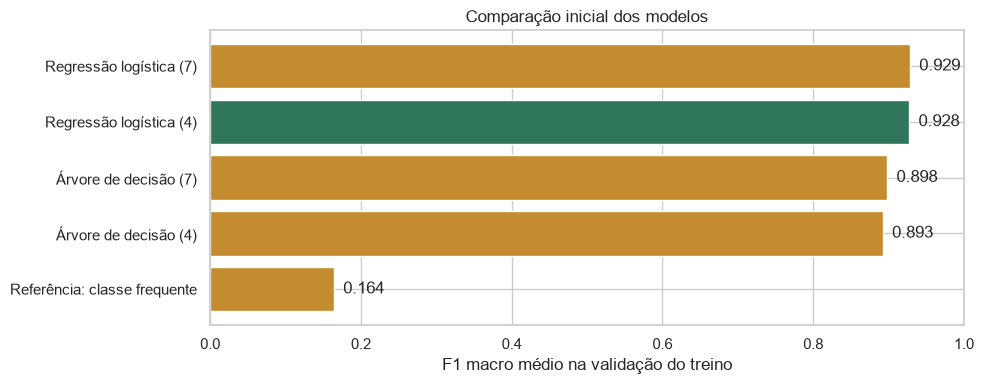

In [11]:
# Mostramos o F1 macro médio de cada candidato para facilitar a comparação visual.
dados_grafico_20_11 = comparacao_modelos_20_11.sort_values("f1_macro_cv")
rotulos_modelos_20_11 = {
    "referencia_classe_mais_frequente": "Referência: classe frequente",
    "arvore_decisao_4": "Árvore de decisão (4)",
    "arvore_decisao_7": "Árvore de decisão (7)",
    "regressao_logistica_4": "Regressão logística (4)",
    "regressao_logistica_7": "Regressão logística (7)",
}
cores_20_11 = [
    "#2F765A" if nome == "regressao_logistica_4" else "#C48B2F"
    for nome in dados_grafico_20_11["modelo"]
]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(dados_grafico_20_11["modelo"].map(rotulos_modelos_20_11), dados_grafico_20_11["f1_macro_cv"], color=cores_20_11)
ax.set(xlim=(0, 1), xlabel="F1 macro médio na validação do treino", title="Comparação inicial dos modelos")
for i, valor in enumerate(dados_grafico_20_11["f1_macro_cv"]):
    ax.text(valor + 0.012, i, f"{valor:.3f}", va="center")
plt.tight_layout()
plt.show()

### 6.2 Escolha do modelo

Na execução registrada desta entrega, a regressão logística teve os maiores F1 médios: **0,9286 com sete atributos** e **0,9276 com quatro**. Como a diferença foi pequena, aplicamos a **regra de 1 erro padrão**: entre os candidatos próximos à maior média, preferimos o que usa menos atributos. A regra orienta uma escolha simples; não prova que os dois modelos sejam estatisticamente iguais.

In [12]:
# Aplicamos a regra de 1 erro padrão ao F1 macro e priorizamos menos atributos.
melhor_cv_20_11 = comparacao_modelos_20_11.iloc[0]
limiar_20_11 = (
    melhor_cv_20_11["f1_macro_cv"]
    - melhor_cv_20_11["desvio_f1_cv"] / np.sqrt(validacao_20_11.n_splits)
)
elegiveis_20_11 = comparacao_modelos_20_11.loc[
    comparacao_modelos_20_11["f1_macro_cv"] >= limiar_20_11
]
escolhido_20_11 = elegiveis_20_11.sort_values(
    ["atributos", "f1_macro_cv", "acuracia_cv", "modelo"],
    ascending=[True, False, False, True],
).iloc[0]
nome_modelo_20_11 = escolhido_20_11["modelo"]
if nome_modelo_20_11 == "referencia_classe_mais_frequente":
    raise RuntimeError("A referência simples venceu; revise a escolha do modelo.")

print(f"Limiar de 1 erro padrão: {limiar_20_11:.4f}")
print(f"Modelo escolhido: {nome_modelo_20_11}")
print(f"F1 macro médio: {escolhido_20_11['f1_macro_cv']:.4f}")

Limiar de 1 erro padrão: 0.9011
Modelo escolhido: regressao_logistica_4
F1 macro médio: 0.9276


### 6.3 Treinamento com os 168 grãos de treino

Depois da escolha por validação cruzada, ajustamos um novo pipeline com **todo o treino**. Ele seleciona quatro medidas por ANOVA, padroniza essas medidas e treina a regressão logística. Salvamos o pipeline completo em `modelos/modelo_20-11.joblib`, que o Colab criará na pasta atual. A acurácia calculada nos próprios dados de treino confirma que o ajuste foi executado; ela **não é uma avaliação final**.

In [13]:
# Treinamos o modelo escolhido com todo o treino, sem consultar os 42 grãos reservados.
from joblib import dump

modelo_20_11 = modelos_20_11[nome_modelo_20_11].fit(X_treino, y_treino)
mascara_20_11 = modelo_20_11.named_steps["selecao"].get_support()
atributos_modelo_20_11 = X_treino.columns[mascara_20_11].tolist()
acertos_treino_20_11 = (modelo_20_11.predict(X_treino) == y_treino).sum()

Path("modelos").mkdir(exist_ok=True)
caminho_modelo_20_11 = Path("modelos/modelo_20-11.joblib")
dump(modelo_20_11, caminho_modelo_20_11)

print("Atributos selecionados:", atributos_modelo_20_11)
print(f"Acertos no próprio treino: {acertos_treino_20_11}/{len(X_treino)}")
print(f"Pipeline salvo em: {caminho_modelo_20_11}")
print("Teste reservado: nenhuma previsão ou avaliação realizada nesta entrega.")

Atributos selecionados: ['area', 'perimetro', 'largura_grao', 'comprimento_sulco']
Acertos no próprio treino: 158/168
Pipeline salvo em: modelos\modelo_20-11.joblib
Teste reservado: nenhuma previsão ou avaliação realizada nesta entrega.


**Conclusão da entrega de 20/11:** a divisão 168/42 foi mantida; a validação no treino indicou regressão logística com quatro atributos; e o pipeline final foi treinado e salvo. Na execução registrada, ele acertou **158 dos 168 grãos usados no próprio ajuste**. Esse número não mede a capacidade de classificar grãos novos. Em 27/11, o modelo será refinado usando somente o treino e, após fixar a configuração, avaliado no teste reservado.